# Fear is contagious too: analysis, results and demonstration
**CITS4403 group project · coupled SIR + risk-perception contagion on N = 1000 networks**

This notebook is the executable companion to the report. It states the research
question and hypotheses, checks the committed sweep data, validates the engine
live, reproduces every headline result with numbers and figures, runs short
live demonstrations suitable for the 10-minute project demo, and records
limitations. Code, equations, text and visualisations are kept together so the
analysis reads as one coherent account.

**How to run:** from the repository root with `requirements.txt` installed,
open this notebook and *Run All*. Inputs live in `data/`
(corrected extinction-complete sweeps plus the mean-field reference). Expected runtime is a
few minutes; the slowest cells are the live N = 1000 demonstrations.

**Frozen model specification:** N = 1000 nodes; β = 0.12 per infected edge per
step; γ = 0.05 recovery probability per step; fear threshold θ = 0.5; caution
effectiveness q = 0.8; broadcast trigger prevalence 0.02; hub pool = top 10%
by degree; 10 initially infected nodes. Topologies: WS (k = 6, p = 0.1),
BA (m = 3), degree-matched ER (p = 6/(n−1)). Final size means the **fraction
of nodes ever infected**, not peak prevalence.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run this notebook from the repo root or notebooks/."
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
FIGS = ROOT / "report" / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
from src.analysis import load_experiments, summarise

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
})
from src.simulation import SimParams, run_coupled

SPEC = dict(N=1000, beta=0.12, gamma=0.05, theta=0.5, q=0.8,
            prev_thresh=0.02, hub_frac=0.1, init_infected=10)
print("ROOT:", ROOT)
print("SPEC:", SPEC)


ROOT: C:\Users\truon\Downloads\4403PROJECT
SPEC: {'N': 1000, 'beta': 0.12, 'gamma': 0.05, 'theta': 0.5, 'q': 0.8, 'prev_thresh': 0.02, 'hub_frac': 0.1, 'init_infected': 10}


## 1 · Data inventory and integrity checks
Corrected sweep files and the homogeneous reference. Row counts, missing values,
unique configuration keys, current model provenance and extinction are asserted.


In [2]:
frames = load_experiments(DATA)
for name, df in frames.items():
    print(f"{name}: {len(df)} rows; all extinct; longest {df.duration.max()} steps")
pilot, zoom, beta_df, mf_runs = (frames[k] for k in
    ["pilot_full", "zoom_h2", "beta_sweep", "mean_field_runs"])
mf_summary = pd.read_csv(DATA / "mean_field_summary.csv")
study = summarise(frames)
for name, table in study.items():
    table.to_csv(DATA / f"{name}_summary.csv", index=False)
print("Full configurations, unique keys and current model fingerprint verified.")


pilot_full: 9090 rows; all extinct; longest 1197 steps
zoom_h2: 3600 rows; all extinct; longest 969 steps
beta_sweep: 600 rows; all extinct; longest 496 steps
mean_field_runs: 80 rows; all extinct; longest 433 steps
Full configurations, unique keys and current model fingerprint verified.


## 2 · Research question and hypotheses
**RQ:** which behavioural-feedback rule minimises epidemic final size *per
unit of social cost* (contacts forgone)? The candidates are **observation**
(local: fear from infected neighbours), **imitation** (social copying of
cautious neighbours), and **broadcast** (global prevalence trigger, uniform
or hub-targeted).

- **H1:** intermediate fear-memory decay produces multi-wave dynamics.
- **H2:** on scale-free (BA) networks hub-targeted nudges dominate; on
  homogeneous networks they do not.
- **H3:** imitation amplifies and overshoots, producing oscillations.

Each hypothesis maps to a section below (§4, §6, §4–§5); the RQ is answered
in §5 and stress-tested in §7. First, the engine must earn trust.


In [3]:
r0 = run_coupled(SimParams(topology="ws", n=300, seed=1, beta=0.0, rule="none"))
r1 = run_coupled(SimParams(topology="ws", n=300, seed=1, gamma=1.0, beta=0.0, rule="none"))
a = run_coupled(SimParams(topology="ba", n=300, seed=42, rule="observation"))
b = run_coupled(SimParams(topology="ba", n=300, seed=42, rule="observation"))
print(f"beta=0  -> final_size = {r0['final_size']:.4f} (expect 10/300 = 0.0333)")
print(f"gamma=1 -> duration = {r1['duration']} steps (fast recovery)")
print(f"determinism: {a['final_size']:.6f} == {b['final_size']:.6f} -> "
      f"{a['final_size'] == b['final_size']}")
assert abs(r0["final_size"] - 10 / 300) < 1e-9
assert r1["duration"] == 1
assert r1["extinct"]
assert np.array_equal(a["prev_series"], b["prev_series"])
assert np.array_equal(a["caut_series"], b["caut_series"])
print("engine validation checks passed")


beta=0  -> final_size = 0.0333 (expect 10/300 = 0.0333)
gamma=1 -> duration = 1 steps (fast recovery)
determinism: 0.613333 == 0.613333 -> True
engine validation checks passed


## 3 · Homogeneous reference comparison
For `rule='none'`, the network simulation is compared with a homogeneous SIR
reference. The ODE uses population fractions with incidence $\beta k s i$
($k = 6$, the network mean degree) and recovery $\gamma i$:

$$\dot s = -\beta k s i, \qquad \dot i = \beta k s i - \gamma i,
  \qquad \dot r = \gamma i.$$

This is a reference approximation, not an exact limit: the engine uses
synchronous discrete-time Bernoulli transmission on a fixed clustered WS
network, while the ODE assumes continuous time and homogeneous mixing.
A gap is expected; its size is itself reportable.


recomputed ODE final @beta=0.03: 0.969848 vs committed 0.969848
 beta   mean    std  ode_final_size
 0.03 0.7512 0.0751          0.9698
 0.06 0.9810 0.0092          0.9993
 0.12 0.9993 0.0011          1.0000
 0.20 1.0000 0.0000          1.0000


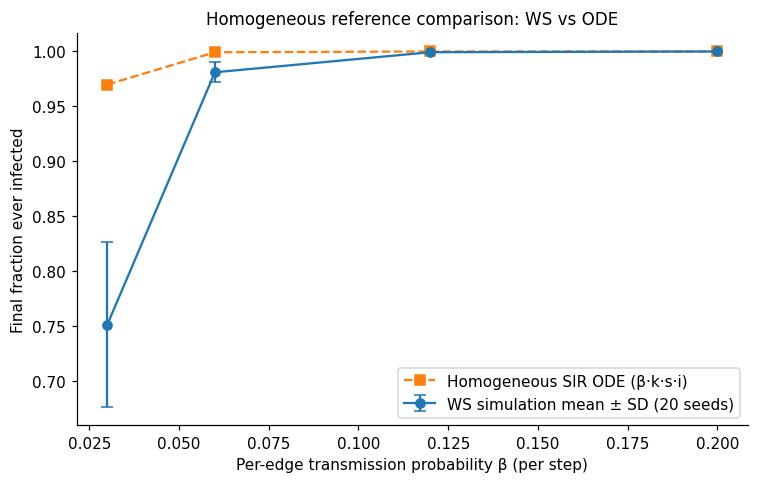

In [4]:
from scipy.integrate import solve_ivp

def ode_final(beta, K=6, gamma=0.05, N=1000, I0=10):
    def rhs(t, y):
        s, i, r = y
        inc = beta * K * s * i
        return [-inc, inc - gamma * i, gamma * i]
    sol = solve_ivp(rhs, (0, 5000), [1 - I0 / N, I0 / N, 0.0],
                    rtol=1e-9, atol=1e-11)
    assert sol.success and abs(sol.y[:, -1].sum() - 1) < 1e-7
    return 1 - sol.y[0, -1]

check = ode_final(0.03)
ref = float(mf_summary.loc[mf_summary.beta == 0.03, "ode_final_size"].iloc[0])
print(f"recomputed ODE final @beta=0.03: {check:.6f} vs committed {ref:.6f}")
assert abs(check - ref) < 1e-6

tab = mf_runs.groupby("beta")["final_size"].agg(["mean", "std"]).reset_index()
tab = tab.merge(mf_summary[["beta", "ode_final_size"]], on="beta")
assert len(tab) == 4
print(tab.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(tab.beta, tab["mean"], yerr=tab["std"], fmt="o-", capsize=4,
            label="WS simulation mean ± SD (20 seeds)")
ax.plot(tab.beta, tab.ode_final_size, "s--", label="Homogeneous SIR ODE (β·k·s·i)")
ax.set(xlabel="Per-edge transmission probability β (per step)",
       ylabel="Final fraction ever infected",
       title="Homogeneous reference comparison: WS vs ODE")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "mean_field.png", dpi=200)
plt.show()


## 4 · Phase structure: coupling × memory
Each cell below averages 30 seeds. Upper row: mean final size under local
observation. Lower row: mean detected wave count under global uniform
broadcast (peak-finding with prominence max(0.01, 0.2 × peak), ≥ 10 steps
apart, which is an algorithmic count rather than a claim of independent
outbreaks).


broadcast detected waves by fear decay δ:
         mean  max
delta            
0.00    1.04    3
0.05   19.10   35
0.15   10.07   25
0.30    4.72   17
0.60    3.00   17

mean oscillation index by rule:
 rule
broadcast        0.833
broadcast_hub    1.316
imitation        1.367
none             1.456
observation      1.237


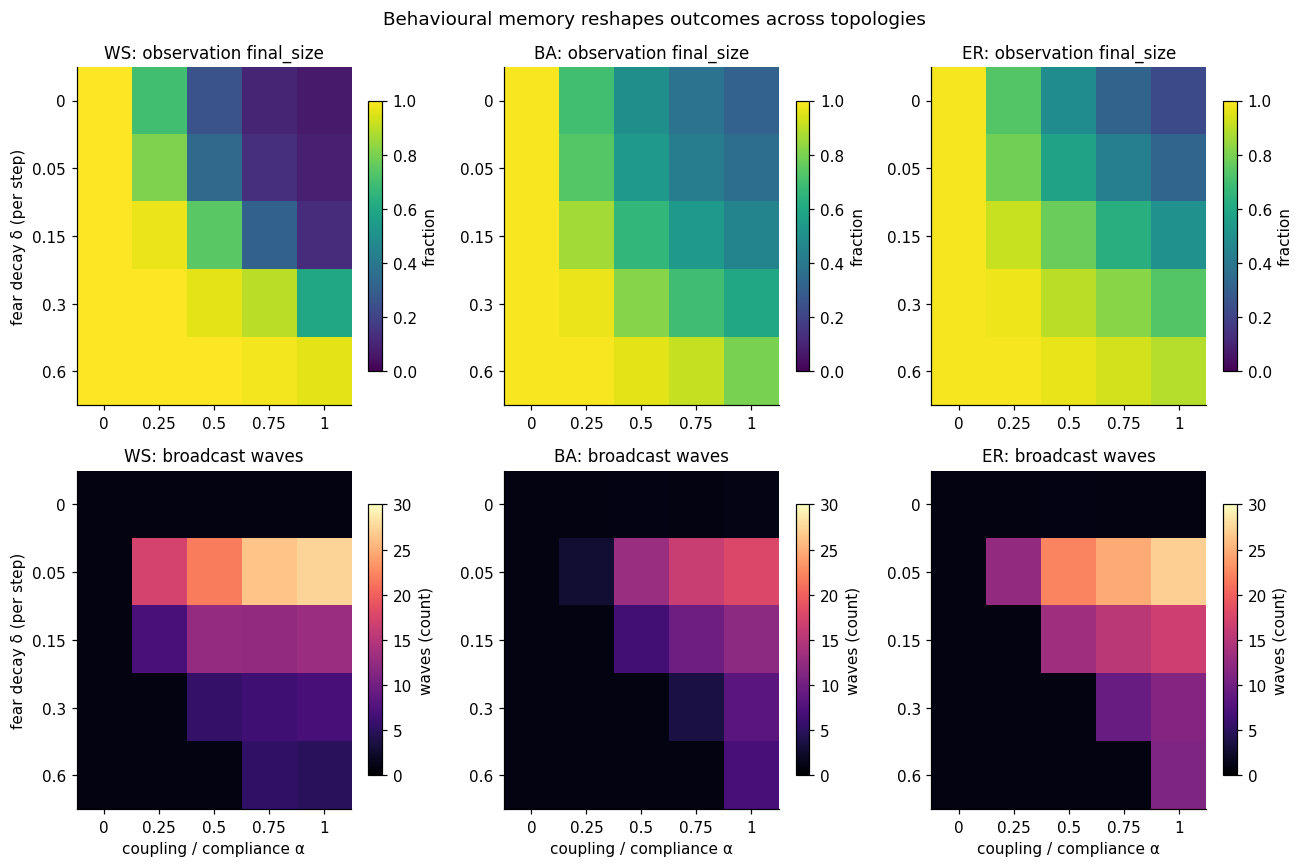

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cfgs = [("observation", "final_size", "viridis", 0, 1),
        ("broadcast", "waves", "magma", 0, 30)]
for col, t in enumerate(["ws", "ba", "er"]):
    for row, (rule, metric, cmap, lo, hi) in enumerate(cfgs):
        piv = (pilot[(pilot.rule == rule) & (pilot.topology == t)]
               .pivot_table(index="delta", columns="alpha",
                            values=metric, aggfunc="mean"))
        assert piv.shape == (5, 5) and piv.notna().all().all()
        ax = axes[row, col]
        im = ax.imshow(piv.values, vmin=lo, vmax=hi, cmap=cmap, aspect="auto")
        ax.set_xticks(range(5), [f"{a:g}" for a in piv.columns])
        ax.set_yticks(range(5), [f"{d:g}" for d in piv.index])
        ax.set_title(f"{t.upper()}: {rule} {metric}")
        if row == 1:
            ax.set_xlabel("coupling / compliance α")
        if col == 0:
            ax.set_ylabel("fear decay δ (per step)")
        plt.colorbar(im, ax=ax, shrink=0.8,
                     label=("fraction" if row == 0 else "waves (count)"))
plt.suptitle("Behavioural memory reshapes outcomes across topologies")
plt.tight_layout()
fig.savefig(FIGS / "phase_panels.png", dpi=200)
plt.show()

bw = pilot[(pilot.rule == "broadcast") & (pilot.alpha > 0)].groupby("delta")["waves"].agg(["mean", "max"])
print("broadcast detected waves by fear decay δ:\n", bw.round(2).to_string())
print("\nmean oscillation index by rule:\n",
      pilot.groupby("rule")["oscillation"].mean().round(3).to_string())


**Reading the panels.** At full observation coupling on WS, mean final size
rises from 0.073 at delta = 0 to 0.961 at delta = 0.6. For positive broadcast
compliance, mean detected waves peak at delta = 0.05 (19.10; maximum 35),
compared with 1.04 at delta = 0. The detector counts prevalence peaks rather
than independent outbreaks, and this finite grid does not establish a phase
transition. H1 is supported for the tested broadcast channel.

**H3 remains unresolved.** Imitation's prevalence coefficient of variation is
1.367, versus 1.456 for no behaviour. This metric mixes peakedness with
fluctuation; neither this ranking nor a large index establishes overshoot.


## 5 · RQ: infections averted per unit protective effort
Efficiency is **N × (mean baseline final fraction − mean rule final fraction)
/ (mean cost + 1)**. The primary degree-aware proxy is
$K_D=(q/2)\sum_t\sum_i c_i(t)k_i$; the retained mean-degree proxy is
$K_M=(q\bar k/2)\sum_t\sum_i c_i(t)$. Units are **edge-steps**, not days.
Both measure endpoint protective effort until extinction, not actual deleted
edges or economic loss. Caution used in each step's transmission is charged
in that same step. Each grid-average point contains 4 positive alpha values
× 5 delta values × 30 seeds = 600 runs. The 95% percentile intervals below
resample paired seed clusters 2,000 times, retaining the shared baseline and
all parameter cells for a seed. They describe uncertainty of the grid average,
not a prediction interval for a single run or an optimised policy frontier.


topology          rule  final_size  social_cost  social_cost_degree  reduction  runs  seeds         eff     eff_low    eff_high  eff_mean_degree  eff_low_mean_degree  eff_high_mean_degree
      ws   observation    0.602785      79466.6               79696   0.396548   600     30   0.0049757  0.00478387  0.00519417       0.00499007           0.00479837             0.0052089
      ba   observation      0.6602       135682              140227   0.330633   600     30  0.00235783  0.00228802  0.00242605       0.00243681           0.00236355            0.00250803
      er   observation    0.695497       133867              140046   0.292037   600     30  0.00208527  0.00200113  0.00217926       0.00218153           0.00209466            0.00227766
      ws     imitation     0.65679       251473              251777   0.342543   600     30   0.0013605    0.001288   0.0014375       0.00136214           0.00128958            0.00143897
      ba     imitation    0.651388       308287             

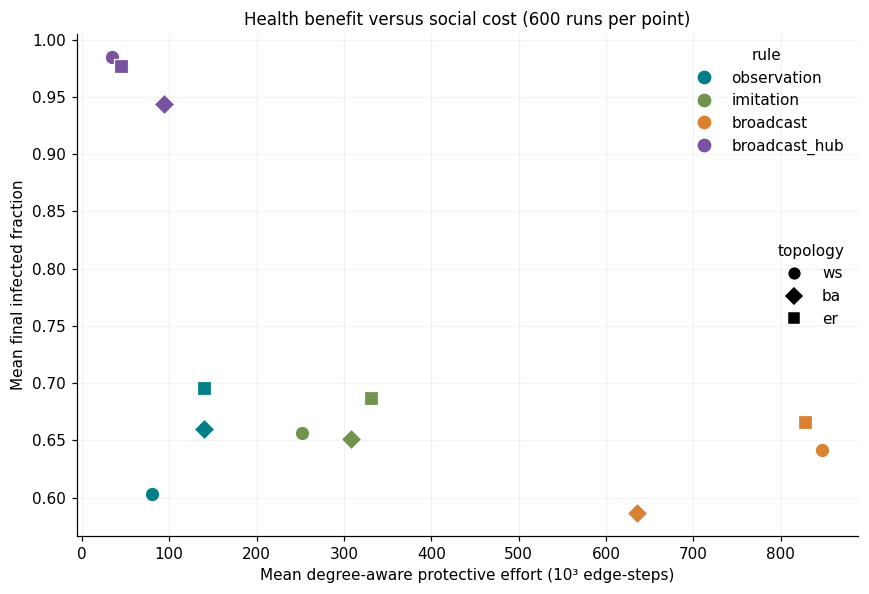

In [6]:
base = pilot[pilot.rule == "none"].groupby("topology")["final_size"].mean()
agg = study["tradeoff"]
print(agg.to_string(index=False, float_format=lambda x: f"{x:.6g}"))
for topo in ["ws", "ba", "er"]:
    winner = agg[agg.topology == topo].iloc[0]
    print(f"{topo.upper()}: highest grid-mean degree-aware efficiency = {winner['rule']} "
          f"({winner['eff']:.5f} infections averted per edge-step)")
cell_winners = (study["cells"].sort_values("eff", ascending=False)
                .groupby(["topology", "alpha", "delta"]).first())
print("Per-cell winners (shared nominal alpha/delta; different rule semantics):")
print(cell_winners.groupby(["topology", "rule"]).size().to_string())
colors = {"observation": "#007f86", "imitation": "#72934e",
          "broadcast": "#d98332", "broadcast_hub": "#7952a2"}
markers = {"ws": "o", "ba": "D", "er": "s"}
fig, ax = plt.subplots(figsize=(8, 5.5))
for _, r in agg.iterrows():
    ax.scatter(r["social_cost_degree"] / 1000, r["final_size"], c=colors[r["rule"]],
               marker=markers[r["topology"]], s=90, edgecolors="white",
               linewidths=0.8, zorder=3)
ax.set(xlabel="Mean degree-aware protective effort (10³ edge-steps)",
       ylabel="Mean final infected fraction",
       title="Health benefit versus social cost (600 runs per point)")
ax.grid(alpha=0.15)
leg1 = ax.legend([Line2D([], [], marker="o", ls="", color=c, markersize=8,
                          label=k) for k, c in colors.items()],
                 list(colors), title="rule", loc="upper right", frameon=False)
ax.add_artist(leg1)
ax.legend([Line2D([], [], marker=m, ls="", color="k", markersize=7,
                   label=t.upper()) for t, m in markers.items()],
          list(markers), title="topology", loc="center right", frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "tradeoff.png", dpi=200)
plt.show()


**Observation has the highest grid-average efficiency on each topology**
under both cost proxies. Under degree-aware accounting it averts about 0.00498,
0.00236 and 0.00209 infections per edge-step on WS, BA and ER respectively.
This does not imply that it wins every parameter cell. On WS, observation's
mean final size is 0.603 versus 0.642 for uniform broadcast; broadcast costs
about 10.6 times as much. Uniform broadcast has lower grid-average final size
on BA and ER, with substantially higher costs. These are grid-weighted
comparisons, not an optimisation frontier or a calibrated policy recommendation.


## 6 · H2: targeting and sensitivity to the cost proxy
The zoom varies per-trigger compliance budget, with 30 seeds × 4 decay values
= 120 runs per point. At budgets ≤ 0.10, policies contact equal expected node
counts **per triggered update**. Uniform draws can recruit new nodes over time;
hub draws remain confined to the same top 10%. Above 0.10 the coverage is no
longer matched. The upper panels show final fractions; lower panels show
degree-aware efficiency with 95% paired seed-bootstrap intervals. The table
also reports mean-degree efficiency to expose cost sensitivity.


                    topology  final_size  social_cost  social_cost_degree  reduction  runs  seeds         eff     eff_low    eff_high  eff_mean_degree  eff_low_mean_degree  eff_high_mean_degree
rule          alpha                                                                                                                                                                              
broadcast     0.02        ba    0.967758      79793.5             79792.2   0.023075   120     30 0.000289185 0.000254675 0.000323234       0.00028918          0.000254453            0.00032404
              0.05        ba    0.916933       124002              123910     0.0739   120     30 0.000596396 0.000568184 0.000626688      0.000595952          0.000566957           0.000626489
              0.08        ba      0.8532       153169              153070   0.137633   120     30 0.000899145 0.000850729 0.000948582      0.000898565          0.000849422            0.00094803
              0.10        ba  

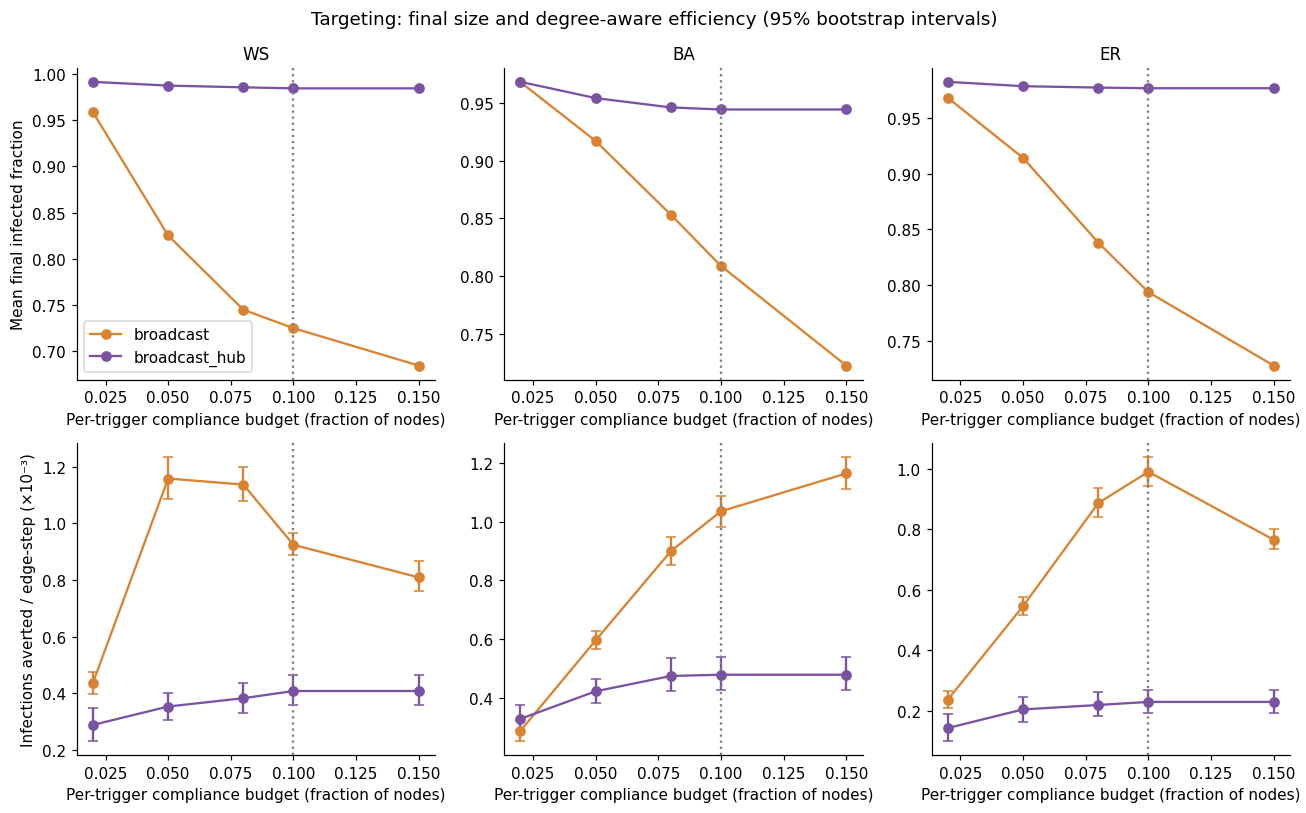

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for col, topo in enumerate(["ws", "ba", "er"]):
    for rule in ["broadcast", "broadcast_hub"]:
        sub = study["zoom"].query("topology == @topo and rule == @rule").sort_values("alpha")
        axes[0, col].plot(sub.alpha, sub.final_size, marker="o", color=colors[rule], label=rule)
        axes[1, col].errorbar(sub.alpha, 1000 * sub.eff,
            yerr=np.array([sub.eff - sub.eff_low, sub.eff_high - sub.eff]) * 1000,
            marker="o", capsize=3, color=colors[rule], label=rule)
    for row in range(2):
        axes[row, col].axvline(0.1, color="grey", ls=":")
        axes[row, col].set_xlabel("Per-trigger compliance budget (fraction of nodes)")
    axes[0, col].set_title(topo.upper())
axes[0, 0].set_ylabel("Mean final infected fraction")
axes[1, 0].set_ylabel("Infections averted / edge-step (×10⁻³)")
axes[0, 0].legend()
plt.suptitle("Targeting: final size and degree-aware efficiency (95% bootstrap intervals)")
fig.tight_layout()
fig.savefig(FIGS / "zoom_h2.png", dpi=200)
plt.show()
zb = study["zoom"].query("topology == 'ba'").set_index(["rule", "alpha"])
print(zb.to_string(float_format=lambda x: f"{x:.6g}"))
for budget in sorted(zoom.alpha.unique()):
    print(f"BA budget {budget:g}: degree-aware hub/uniform efficiency ratio "
          f"{zb.loc[('broadcast_hub', budget), 'eff'] / zb.loc[('broadcast', budget), 'eff']:.3f}")


**H2 is cost-sensitive and is not generally supported.** Under mean-degree
accounting, hub targeting has higher BA efficiency at every budget. Weighting
its actual contacts removes most of that advantage: its point estimate is
higher only at budget 0.02 (0.000330 versus 0.000289); uniform wins at budgets
0.05–0.15. The hub final fraction plateaus near 0.944 from budget 0.10 upward,
while uniform falls from 0.809 to 0.723. This ceiling is imposed by the fixed
pool. WS and ER have smaller raw benefits from targeting, and neither the
per-trigger budget nor the mean-degree proxy guarantees equal cumulative cost.


## 7 · Robustness: transmission sweep and topology
`beta_sweep.csv` varies per-edge transmission β from 0.03 to 0.20 (20 seeds),
comparing no behaviour with observation at α = 0.75, δ = 0.10. Bands show ±1
sample SD across seeds (descriptive variability, not confidence intervals).


lowest final size under observation, by β:
 beta
0.03    ws
0.06    ws
0.09    ws
0.12    ws
0.20    ws
WS is the most suppressible topology at every β: confirmed


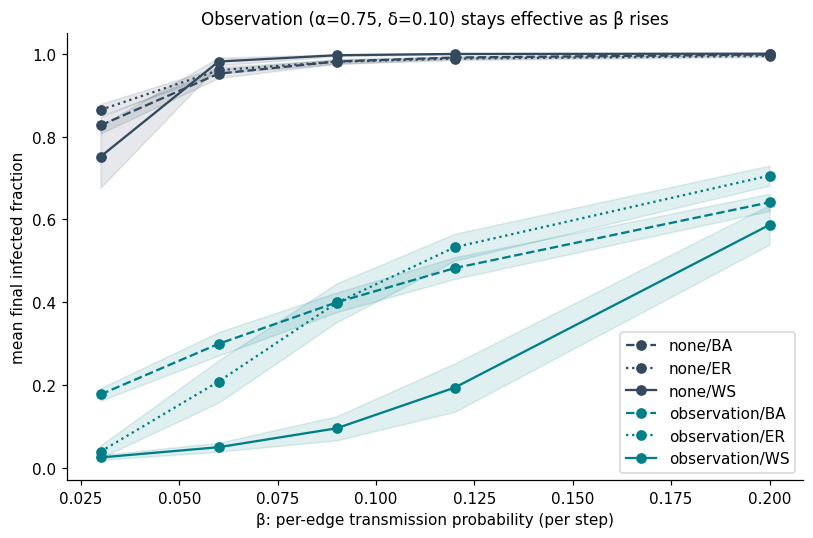

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
beta_colors = {"none": "#34495e", "observation": "#007f86"}
beta_styles = {"ws": "-", "ba": "--", "er": ":"}
for (rule, topo), sub in beta_df.groupby(["rule", "topology"]):
    g = sub.groupby("beta")["final_size"].agg(["mean", "std"])
    ax.plot(g.index, g["mean"], marker="o", linestyle=beta_styles[topo],
            color=beta_colors[rule], label=f"{rule}/{topo.upper()}")
    ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"],
                    color=beta_colors[rule], alpha=0.12)
ax.set(xlabel="β: per-edge transmission probability (per step)",
       ylabel="mean final infected fraction",
       title="Observation (α=0.75, δ=0.10) stays effective as β rises")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "beta_sweep.png", dpi=200)
plt.show()
obs = beta_df[beta_df.rule == "observation"]
mins = (obs.groupby(["beta", "topology"])["final_size"].mean()
        .unstack().idxmin(axis=1))
print("lowest final size under observation, by β:\n", mins.to_string())
assert (mins == "ws").all()
print("WS is the most suppressible topology at every β: confirmed")


No-behaviour final fractions approach one at high transmission. Observation
at alpha = 0.75, delta = 0.10 holds WS to 0.587 at beta = 0.20. WS has the
lowest observation final size at each tested beta. This checks observation's
effect against its baseline; because other rules are absent from this sweep,
it does not establish their efficiency ordering across beta.


## 8 · Live demonstrations (10-minute demo run-of-show)
Three short demos below re-run the merged engine live: (A) a same-seed
rule comparison, (B) trajectory shapes that motivate the phase panels, and
(C) sensitivity to the broadcast trigger assumption. Suggested timing:
1 min motivation + RQ, 2 min model/equations, 4 min results (§4–§7 figures),
2 min live demos, 1 min limitations.


In [9]:
rows = []
for rule in ["none", "observation", "imitation", "broadcast", "broadcast_hub"]:
    out = run_coupled(SimParams(topology="ws", n=1000, seed=11, beta=0.12,
                                rule=rule, alpha=0.5, p_comply=0.5))
    rows.append((rule, round(out["final_size"], 3), int(out["social_cost_degree"]),
                 out["waves"], out["duration"]))
demoA = pd.DataFrame(rows, columns=["rule", "final_size",
                                    "degree-aware cost (edge-steps)", "waves",
                                    "duration (steps)"])
print("Demo A: same seed (11), WS, N=1000, β=0.12:")
print(demoA.to_string(index=False))


Demo A: same seed (11), WS, N=1000, β=0.12:
         rule  final_size  degree-aware cost (edge-steps)  waves  duration (steps)
         none       1.000                               0      1               141
  observation       0.631                          114721      1               257
    imitation       0.642                          260863      1               135
    broadcast       0.799                         1218273     15               902
broadcast_hub       0.982                           30786      1               152


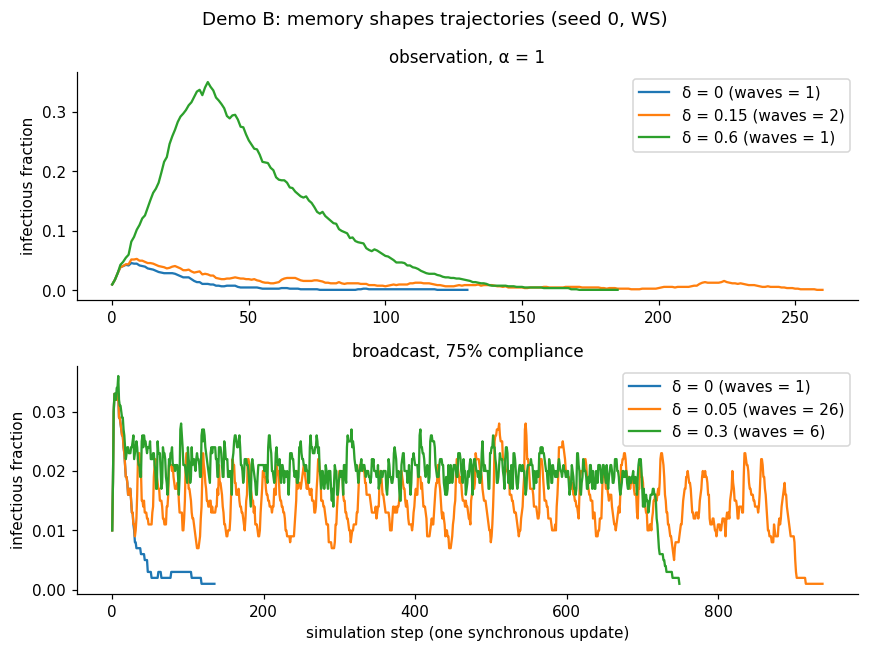

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6))
cases = [("observation", 1.0, (0.0, 0.15, 0.6), "observation, α = 1"),
         ("broadcast", 0.75, (0.0, 0.05, 0.3), "broadcast, 75% compliance")]
for ax, (rule, alpha, deltas, title) in zip(axes, cases):
    for d in deltas:
        out = run_coupled(SimParams(topology="ws", n=1000, seed=0, beta=0.12,
                                    rule=rule, alpha=alpha, p_comply=alpha,
                                    delta=d))
        ax.plot(out["prev_series"], label=f"δ = {d:g} (waves = {out['waves']})")
    ax.set_title(title)
    ax.set_ylabel("infectious fraction")
    ax.legend()
axes[1].set_xlabel("simulation step (one synchronous update)")
plt.suptitle("Demo B: memory shapes trajectories (seed 0, WS)")
plt.tight_layout()
fig.savefig(FIGS / "timeseries.png", dpi=200)
plt.show()


In [11]:
print("Demo C: broadcast trigger sensitivity (WS, N=300, seed 0, "
      "α=0.75, δ=0.05):")
for thr in (0.01, 0.02, 0.05):
    out = run_coupled(SimParams(topology="ws", n=300, seed=0, beta=0.12,
                                rule="broadcast", alpha=0.75, delta=0.05,
                                prev_thresh=thr, p_comply=0.75))
    print(f"  trigger={thr}: final={out['final_size']:.3f}, "
          f"waves={out['waves']}, duration={out['duration']}")


Demo C: broadcast trigger sensitivity (WS, N=300, seed 0, α=0.75, δ=0.05):
  trigger=0.01: final=0.117, waves=3, duration=215
  trigger=0.02: final=0.203, waves=7, duration=259
  trigger=0.05: final=0.817, waves=15, duration=462


## 9 · Limitations
- All networks are synthetic; results are comparative rather than predictions
  for real populations. Degree matching does not remove clustering differences.
- Cost proxies measure protective effort until extinction; they neither delete
  edges nor measure economic losses. Residual caution after extinction is not
  charged. The timestep is not calibrated to days.
- A fixed 0.02 broadcast trigger and a fixed top-10% hub pool constrain outcomes.
  Equal expected recipients per trigger do not imply equal unique recipients
  or equal cumulative protective effort.
- Imitation uses half-decay: the same nominal delta differs in effective memory.
  A common effective-decay comparison is an extension, not tested here.
- Peak counts depend on prominence and distance. The coefficient of variation
  cannot distinguish oscillation or overshoot from a single peaked epidemic.
- The beta sweep tests observation versus no behaviour, not the ordering of all
  rules. Grid-average efficiency depends on the chosen parameter weights.
- Bootstrap intervals quantify uncertainty across seed clusters for fixed grids;
  they do not include uncertainty in model rules, cost interpretation or topology.
- The continuous-time homogeneous ODE is a reference approximation. The low-beta
  gap is reported, but clustering and discrete-time effects have not been isolated.

Extensions: empirical contact networks, equal effective memory, adaptive
triggers, cost-matched policy frontiers, and wave-detection sensitivity checks.


## 10 · Conclusion
Observation has the highest grid-average efficiency under both cost proxies.
Extinction-complete simulations remove the apparent WS final-size advantage
of broadcast seen at the old 500-step cutoff. Intermediate positive decay
produces the most detected broadcast peaks (H1, within the tested grid).
Hub efficiency depends strongly on cost accounting and does not generally
dominate after degree weighting (H2). The oscillation index does not establish
imitation overshoot (H3 unresolved). These conclusions apply to the specified
synthetic networks, response rules and parameter grids.


In [12]:
import matplotlib as _mpl, scipy as _sp, networkx as _nx
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"matplotlib {_mpl.__version__}, scipy {_sp.__version__}, "
      f"networkx {_nx.__version__}")
print("rows:", {k: len(v) for k, v in
      {"pilot_full": pilot, "zoom_h2": zoom, "beta_sweep": beta_df,
       "mean_field_runs": mf_runs}.items()})
print("executed (UTC):", time.strftime("%Y-%m-%d %H:%M", time.gmtime()))
print("All inline assertions passed; figures and tables above are live outputs.")


numpy 2.3.3, pandas 2.3.3, matplotlib 3.10.7, scipy 1.16.2, networkx 3.5
rows: {'pilot_full': 9090, 'zoom_h2': 3600, 'beta_sweep': 600, 'mean_field_runs': 80}
executed (UTC): 2026-10-06 22:16
All inline assertions passed; figures and tables above are live outputs.
